# D10. ASR 평가 + 미니 프로젝트: WER · CER · 한국어 정규화 · 자동 회의록 생성기

**음성 AI 전문가 과정 (160h) | 2주차 M2 | 4시간 | 금요일 미니 프로젝트**

## 학습 목표
1. **WER · CER**이 무엇을 세는지(바꿈 S · 빠짐 D · 끼어듦 I) 알고, **편집 거리**를 직접 계산해 jiwer와 같은 값을 낸다.
2. 한국어 받아쓰기 채점이 까다로운 이유(띄어쓰기 · 숫자 · 영어 표기 · 문장 부호)를 알고, **정규화 함수**를 만들어 공정하게 잰다.
3. D8 · D9에서 배운 부품(WhisperX · 화자 분리 · 단어에 화자)을 **함수 하나로 조립**한다.
4. **LLM(Claude)** 에게 녹취를 넘겨 **요약 · 결정 사항 · 할 일**을 JSON으로 받는다 (API 키가 없으면 규칙 기반으로 대신).
5. 만든 회의록 생성기를 **단계별로 평가**(CER · 화자 정확도 · 요약 점검)하고, **Gradio 화면**으로 시연한다.

## 오늘의 실습 흐름
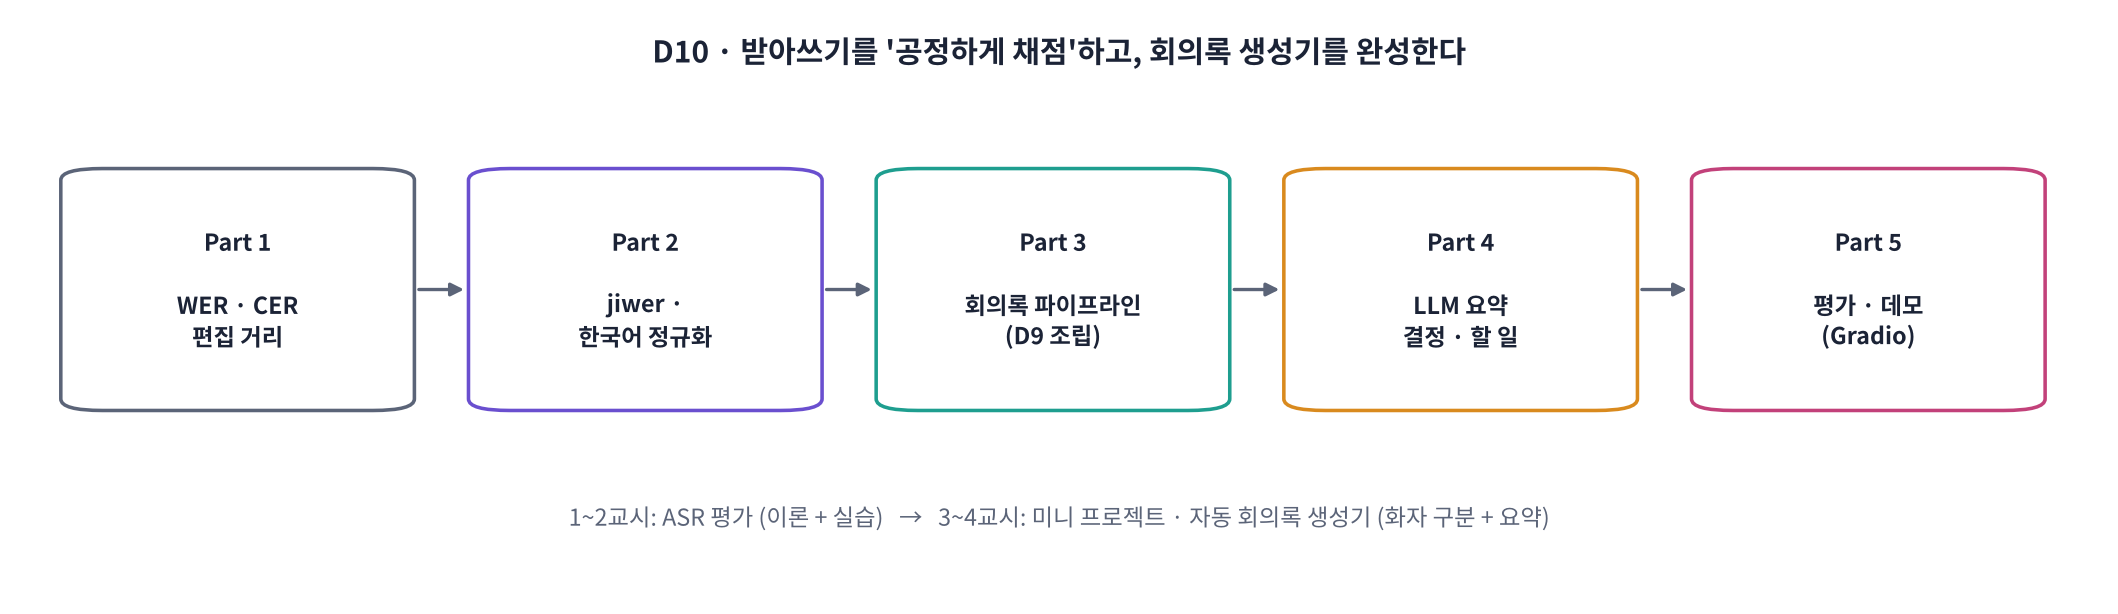

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | WER · CER의 뜻, 편집 거리 표 직접 채우기 | Part 0 ~ 1, 워크시트 1교시 |
| 2교시 | jiwer, 한국어 채점의 함정 다섯 가지, 정규화 함수 만들기 | Part 2, 워크시트 2교시 |
| 3교시 | 🛠️ 미니 프로젝트 ①: 회의록 파이프라인 조립 (받아쓰기 · 정렬 · 화자 분리 · 줄 묶기) | Part 3, 워크시트 3교시 |
| 4교시 | 🛠️ 미니 프로젝트 ②: LLM 요약 · 평가 · Gradio 데모 · 발표 | Part 4 ~ 6, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day10/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day10/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 셀은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- 🛠️ **미니 프로젝트** 셀은 그대로 실행해도 동작합니다. 시간이 남으면 `✏️ 바꿔 보기` 표시된 곳을 고쳐 나만의 회의록 생성기로 만드세요.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 필요한 식 하나와 "읽는 법" |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🔍 **코드 해설** | 주요 코드를 한 줄씩 |

> ⚙️ **T4 GPU 런타임을 권장합니다** ([런타임] → [런타임 유형 변경] → **T4 GPU**).
>
> 🔑 **선택 사항 두 가지** (Colab 왼쪽 🔑 보안 비밀에 저장): `HF_TOKEN`(D9의 pyannote 화자 분리), `ANTHROPIC_API_KEY`(Part 4의 Claude 요약). **둘 다 없어도** 직접 만든 화자 분리와 규칙 기반 요약으로 끝까지 진행됩니다.

> 🎬 **애니메이션 D10-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#flow) — Part 1~5 로드맵

## Part 0. 준비

D9와 같은 **WhisperX** · **SpeechBrain** · **edge-tts** · **jiwer**에, 오늘은 **anthropic**(Claude API)과 **gradio**(데모 화면)를 더합니다.

> ⚠️ **설치에 3~5분 걸립니다**(WhisperX가 PyTorch 2.8을 함께 설치). 끝난 뒤 Colab이 "세션 다시 시작"을 권하면 다시 시작하고 **설치 셀은 건너뛰고** 그다음 셀부터 실행하세요.

In [ ]:
!pip install -q whisperx edge-tts gTTS jiwer speechbrain anthropic gradio
print("✅ 설치 완료")

In [ ]:
import os, time, re, json, subprocess
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import torch
import jiwer
from IPython.display import Audio, Markdown, display
from gtts import gTTS

SR = 16000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CT = "float16" if DEVICE == "cuda" else "int8"
torch.manual_seed(0); np.random.seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def secret(name):                                  # Colab 🔑 보안 비밀 → 환경 변수 순서로 찾기
    v = os.environ.get(name)
    try:
        from google.colab import userdata
        v = v or userdata.get(name)
    except Exception:
        pass
    return v

HF_TOKEN = secret("HF_TOKEN")
ANTHROPIC_API_KEY = secret("ANTHROPIC_API_KEY")
print(f"torch {torch.__version__} | device = {DEVICE} | compute_type = {CT}")
print("HF_TOKEN:", "✅ 있음 (pyannote)" if HF_TOKEN else "❌ 없음 → 직접 만든 화자 분리 (D9 Part 4)")
print("ANTHROPIC_API_KEY:", "✅ 있음 (Claude 요약)" if ANTHROPIC_API_KEY else "❌ 없음 → 규칙 기반 요약")

### 0-1. 시험 음성 두 가지
1. **채점 연습용 문장 6개** (Part 1~2): 숫자 · 영어 · 문장 부호가 섞인 문장을 gTTS로 읽힙니다. 정답(`REFS`)은 **사람이 받아 적듯이** 숫자와 영어를 그대로 썼습니다.
2. **회의 녹음** (Part 3~5): D9처럼 세 사람이 번갈아 말하는 회의입니다. 이번에는 **결정 사항과 할 일**이 들어 있어 요약을 시험할 수 있습니다.

In [ ]:
def tts_g(text, path):
    gTTS(text, lang="ko").save(path)
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=35)
    return y.astype(np.float32)

REFS = [
    "회의는 오후 3시에 시작합니다.",
    "Whisper 모델로 받아쓰기를 했습니다.",
    "다음 주까지 API 문서를 정리해 주세요.",
    "예산은 2500만 원으로 정했습니다.",
    "10월 20일에 결과를 공유하겠습니다.",
    "음성 인식 정확도를 CER로 평가합니다.",
]
eval_clips = [tts_g(s, f"e{i}.mp3") for i, s in enumerate(REFS)]
print(f"채점 연습 문장 {len(REFS)}개 ({sum(len(c) for c in eval_clips) / SR:.1f}초)")
display(Audio(eval_clips[0], rate=SR))

In [ ]:
# 회의 녹음 (D9 방식): edge-tts 세 목소리, 안 되면 gTTS + 음높이 바꾸기
VOICES = {"김팀장": ("ko-KR-InJoonNeural", -5), "이연구원": ("ko-KR-SunHiNeural", 2), "박대리": ("ko-KR-HyunsuMultilingualNeural", -2)}
SCRIPT = [
    ("김팀장", "오늘은 회의록 생성기 개발 일정을 정하겠습니다."),
    ("이연구원", "받아쓰기는 위스퍼 스몰 모델을 그대로 쓰기로 했습니다."),
    ("박대리", "화자 분리는 파이아노트를 쓰고, 토큰이 없으면 직접 만든 방법을 쓰겠습니다."),
    ("김팀장", "좋습니다. 그렇게 결정하겠습니다."),
    ("이연구원", "평가는 정규화를 한 뒤에 글자 오류율로 하겠습니다."),
    ("박대리", "저는 수요일까지 단어 시각 정렬을 붙이겠습니다."),
    ("이연구원", "저는 목요일까지 평가 스크립트를 만들겠습니다."),
    ("김팀장", "그럼 금요일 오후에 결과를 같이 검토합시다."),
]

def tts_edge(text, voice, path):
    r = subprocess.run(["edge-tts", "--voice", voice, "--text", text, "--write-media", path], capture_output=True, text=True, timeout=60)
    if r.returncode != 0 or not os.path.exists(path) or os.path.getsize(path) < 2000:
        raise RuntimeError(r.stderr[-200:])

try:
    tts_edge("시험", VOICES["김팀장"][0], "probe.mp3"); USE_EDGE = True
except Exception:
    USE_EDGE = False
print("목소리:", "edge-tts (세 목소리)" if USE_EDGE else "gTTS + 음높이 바꾸기")

def say(name, text, path):
    voice, semi = VOICES[name]
    if USE_EDGE:
        tts_edge(text, voice, path); y, _ = librosa.load(path, sr=SR, mono=True)
    else:
        y = tts_g(text, path); y = librosa.effects.pitch_shift(y, sr=SR, n_steps=semi)
    y, _ = librosa.effects.trim(y, top_db=35)
    return (0.9 * y / np.abs(y).max()).astype(np.float32)

rng = np.random.default_rng(0)
pieces, TURNS, t = [np.zeros(int(0.5 * SR), np.float32)], [], 0.5
for i, (name, text) in enumerate(SCRIPT):
    y = say(name, text, f"turn{i}.mp3")
    TURNS.append(dict(speaker=name, text=text, start=round(t, 3), end=round(t + len(y) / SR, 3)))
    gap = rng.uniform(0.5, 0.9); pieces += [y, np.zeros(int(gap * SR), np.float32)]; t += len(y) / SR + gap
meeting = np.concatenate(pieces)
ENROLL = {n: say(n, f"안녕하세요. 저는 {n}입니다. 잘 부탁드립니다.", f"enroll_{n}.mp3") for n in VOICES}
REF_MEETING = " ".join(x for _, x in SCRIPT)
print(f"회의 녹음 {len(meeting) / SR:.1f}초, 발화 {len(TURNS)}개")
display(Audio(meeting, rate=SR))

## Part 1. WER · CER: 받아쓰기를 몇 점으로 매기나

> 💬 **쉽게 말하면**: 정답 문장을 만들려면 인식 결과를 **빨간 펜으로 몇 번 고쳐야 하나**를 셉니다. 고치는 방법은 세 가지: **바꾸기(S)**, **지우기(I, 결과에 끼어든 것)**, **넣기(D, 결과에서 빠진 것)**. 그 횟수를 정답 길이로 나눈 것이 오류율입니다. 단어 단위면 **WER**, 글자 단위면 **CER**.

> 🍎 **비유: 받아쓰기 시험 채점.** 선생님이 학생 답안지를 정답과 비교하며 빨간 펜으로 고칩니다. 틀린 글자를 고치고(바꿈), 빠뜨린 글자를 끼워 넣고(빠짐), 쓸데없이 쓴 글자를 지웁니다(끼어듦). **빨간 펜 자국이 적을수록** 잘 쓴 답안입니다. 단, 같은 답안이라도 **가장 적게 고치는 방법**으로 셉니다.

> 📐 **핵심 식 하나**: `WER = (S + D + I) ÷ N`
>
> **읽는 법**: "정답 단어 N개 중 몇 개를 고쳐야 했나." S 바꿈, D 빠짐(deletion), I 끼어듦(insertion). CER은 같은 식을 **글자** 단위로. 끼어든 것이 많으면 **100%를 넘을 수도** 있습니다.

| 용어 | 예 (정답 → 결과) | 세는 법 |
|---|---|---|
| **S** 바꿈 (substitution) | 세 → 3시에 | 1 |
| **D** 빠짐 (deletion) | 시작합니다 → (없음) | 1 |
| **I** 끼어듦 (insertion) | (없음) → 바로 | 1 |
| **N** | 정답의 단어(글자) 수 | 분모 |

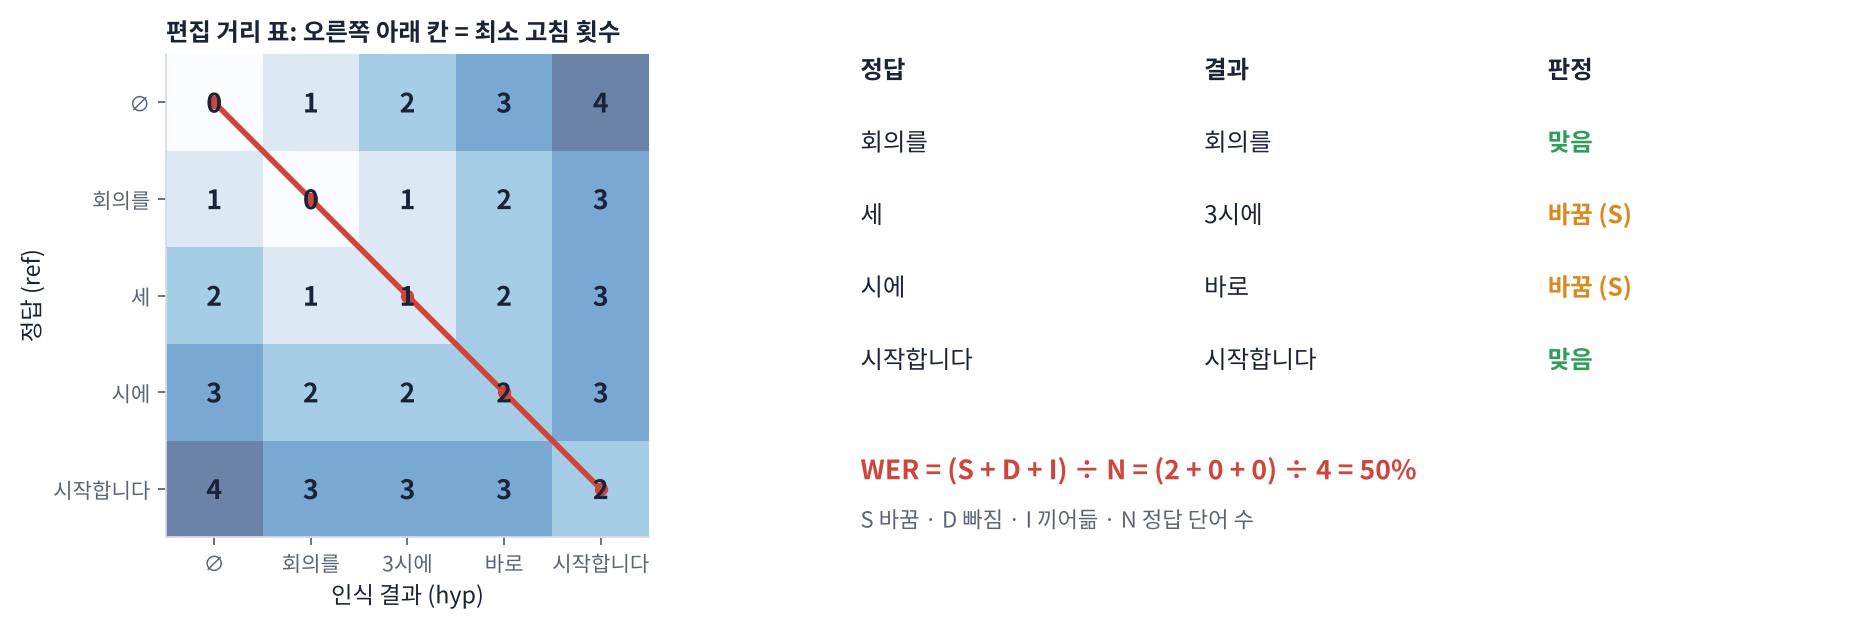

> 🎬 **애니메이션 D10-2:** [편집 거리 표 채우기](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#editdist) — 칸을 하나씩 채우고 가장 적게 고치는 길 찾기

### 🧩 빈칸 실습 1: 편집 거리 표 채우기
표의 칸 `d[i][j]`는 "정답 앞 i개를 결과 앞 j개로 바꾸는 최소 고침 횟수"입니다. 세 방향 중 가장 작은 것을 고릅니다.
- 위에서 오기 `d[i-1][j] + 1`: 정답 단어 하나가 **빠짐**
- 왼쪽에서 오기 `d[i][j-1] + 1`: 결과에 단어 하나가 **끼어듦**
- 대각선에서 오기 `d[i-1][j-1] + cost`: 두 단어가 같으면 0, 다르면 **바꿈** 1

대각선에서 올 때 더하는 값의 이름을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 1
def edit_distance(r, h):
    n, m = len(r), len(h)
    d = np.zeros((n + 1, m + 1), dtype=int)
    d[:, 0] = np.arange(n + 1)                      # 결과가 비었으면 정답을 모두 '빠짐'
    d[0, :] = np.arange(m + 1)                      # 정답이 비었으면 결과가 모두 '끼어듦'
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if r[i - 1] == h[j - 1] else 1
            d[i, j] = min(d[i - 1, j] + 1,           # 빠짐 (D)
                          d[i, j - 1] + 1,           # 끼어듦 (I)
                          d[i - 1, j - 1] + ____)    # 같음(0) 또는 바꿈 (S)
    return d

ref = "회의를 세 시에 시작합니다".split()
hyp = "회의를 3시에 바로 시작합니다".split()
d = edit_distance(ref, hyp)
print(pd.DataFrame(d, index=["-"] + ref, columns=["-"] + hyp))
print("\n최소 고침 횟수 =", d[-1, -1])
check(d[-1, -1] == 2 and edit_distance(list("abc"), list("abd"))[-1, -1] == 1, hint="두 단어가 같으면 0, 다르면 1인 변수 cost 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
d[i - 1, j - 1] + cost
```

**해설**: 오른쪽 아래 칸 `d[n, m]`이 정답 전체를 결과 전체로 바꾸는 **최소** 고침 횟수입니다. 이 예에서는 '세→3시에', '시에→바로' 두 번 바꾸면 됩니다(S=2). '세'를 지우고 '바로'를 끼워 넣는 등 다른 방법도 있지만 횟수가 더 많아서 고르지 않습니다. D6의 CTC · D9의 격자와 같은 **동적 계획법**(작은 문제의 답을 표에 적어 가며 큰 문제를 푸는 방법)입니다.

</details>

### 🧩 빈칸 실습 2: WER · CER 직접 계산하기
고침 횟수를 **정답의 길이(N)** 로 나눕니다. 단어로 나누면 WER, 글자로 나누면 CER입니다. 분모에 들어갈 값을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 2
def error_rate(r, h):
    return edit_distance(r, h)[-1, -1] / ____

def my_wer(ref, hyp):
    return error_rate(ref.split(), hyp.split())

def my_cer(ref, hyp):
    return error_rate(list(ref), list(hyp))                 # 공백도 한 글자로 셈 (jiwer와 같음)

pairs = [("회의를 세 시에 시작합니다", "회의를 3시에 바로 시작합니다"),
         ("회의록 생성기를 만들어 봅시다", "회의록생성기를 만들어봅시다"),
         ("네 좋습니다", "네 네 네 좋습니다 감사합니다")]
for r, h in pairs:
    print(f"정답: {r}\n결과: {h}")
    print(f"  WER 직접 {my_wer(r, h):6.1%} | jiwer {jiwer.wer(r, h):6.1%}   ·   CER 직접 {my_cer(r, h):6.1%} | jiwer {jiwer.cer(r, h):6.1%}\n")
check(all(abs(my_wer(r, h) - jiwer.wer(r, h)) < 1e-9 and abs(my_cer(r, h) - jiwer.cer(r, h)) < 1e-9 for r, h in pairs),
      hint="분모는 정답의 길이 len(r) 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return edit_distance(r, h)[-1, -1] / len(r)
```

**해설**: 분모는 **정답**의 길이입니다(결과의 길이가 아님). 두 번째 예는 띄어쓰기만 다른데 WER은 100%, CER은 12.5%입니다. 세 번째 예는 끼어든 단어가 많아 **WER이 150%** 로 100%를 넘습니다. 그래서 "WER 30%"라는 말만 듣고 "70%는 맞혔구나"라고 생각하면 안 됩니다.

</details>

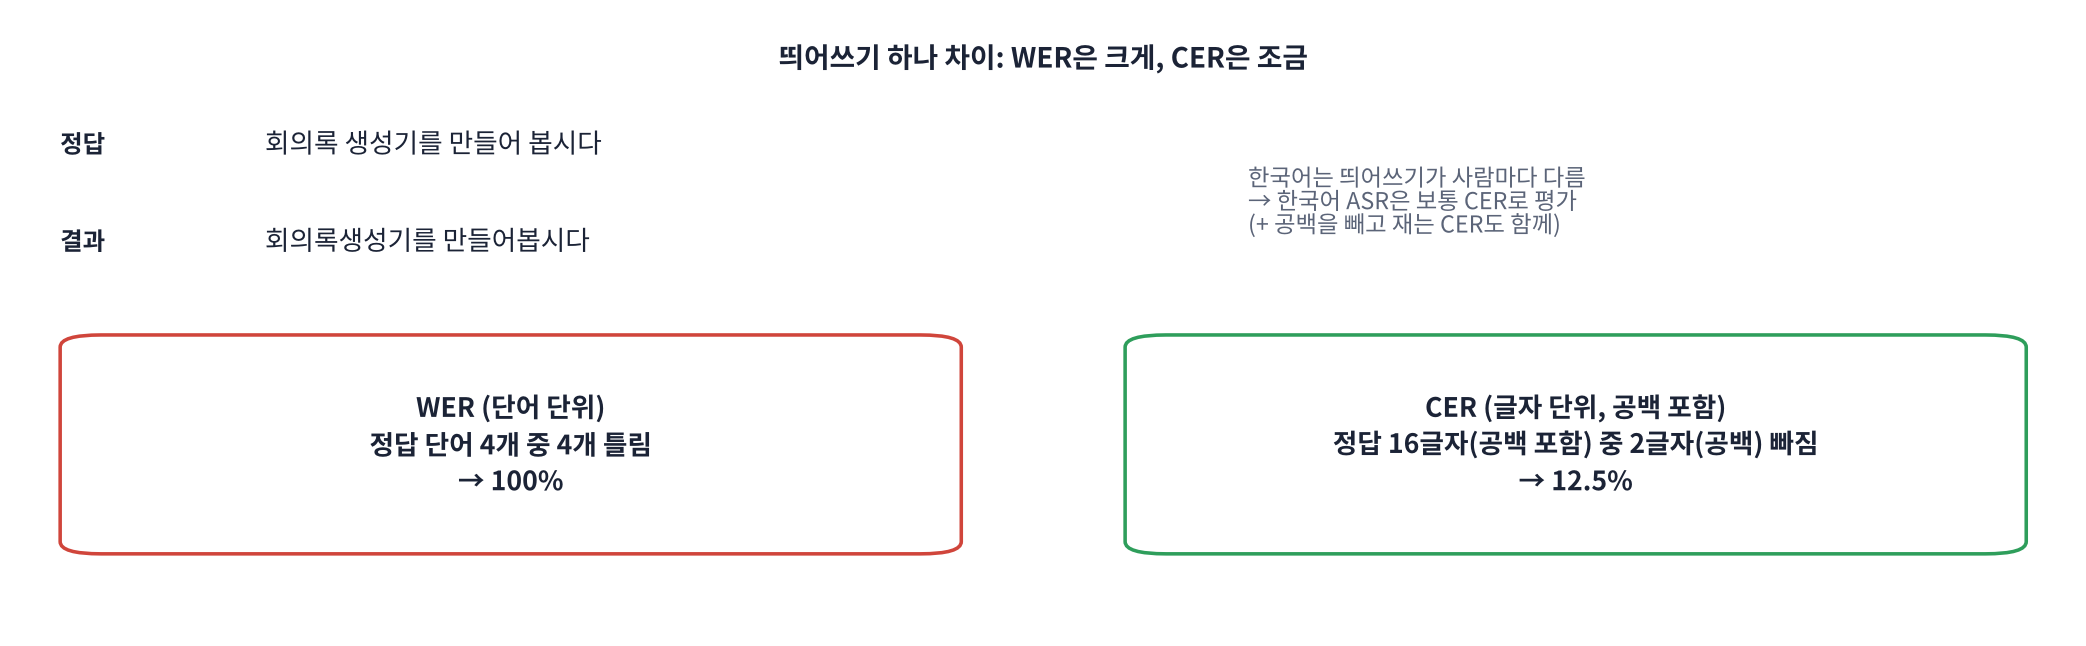

**결과 읽기**: 한국어는 띄어쓰기가 사람마다, 모델마다 다릅니다. 띄어쓰기 하나로 WER이 크게 출렁이므로 **한국어 ASR은 보통 CER로 평가**합니다(영어는 WER). 띄어쓰기를 아예 무시하려면 공백을 지운 뒤 CER을 재기도 합니다(Part 2).

> 🎬 **애니메이션 D10-3:** [WER vs CER](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#wercer) — 결과 문장을 고쳐 보며 S · D · I와 두 오류율이 어떻게 변하는지

**❓ 생각해 보기**: CER이 0%면 그 받아쓰기는 완벽할까요? 반대로 WER이 높으면 쓸모없을까요?

<details>
<summary>답 보기</summary>

CER 0%는 정답과 **글자가 똑같다**는 뜻이라 완벽합니다. 하지만 높은 WER이 꼭 쓸모없다는 뜻은 아닙니다. 띄어쓰기 · 숫자 표기('3시' vs '세 시') · 영어 표기('Whisper' vs '위스퍼')처럼 **뜻은 같은데 글자가 다른** 경우도 오류로 세기 때문입니다. 반대로 '했습니다' → '안 했습니다'처럼 **한 글자 차이로 뜻이 뒤집히는** 오류는 CER로는 작아 보입니다. 숫자는 판단의 시작일 뿐, 틀린 곳을 직접 읽어 봐야 합니다.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day10/worksheet.html)** — S · D · I, WER 식과 분모, 100%를 넘는 WER, 편집 거리 표의 세 방향, 최소 고침, 한국어에서 CER을 쓰는 이유
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 2. jiwer와 한국어 정규화: 공정하게 채점하기

> 💬 **쉽게 말하면**: Whisper가 '오후 세 시'라고 받아 적고 정답은 '오후 3시'라면 틀린 걸까요? 뜻은 같습니다. **정답과 결과를 같은 규칙으로 다듬은 뒤(정규화)** 비교해야 모델의 진짜 실력이 보입니다.

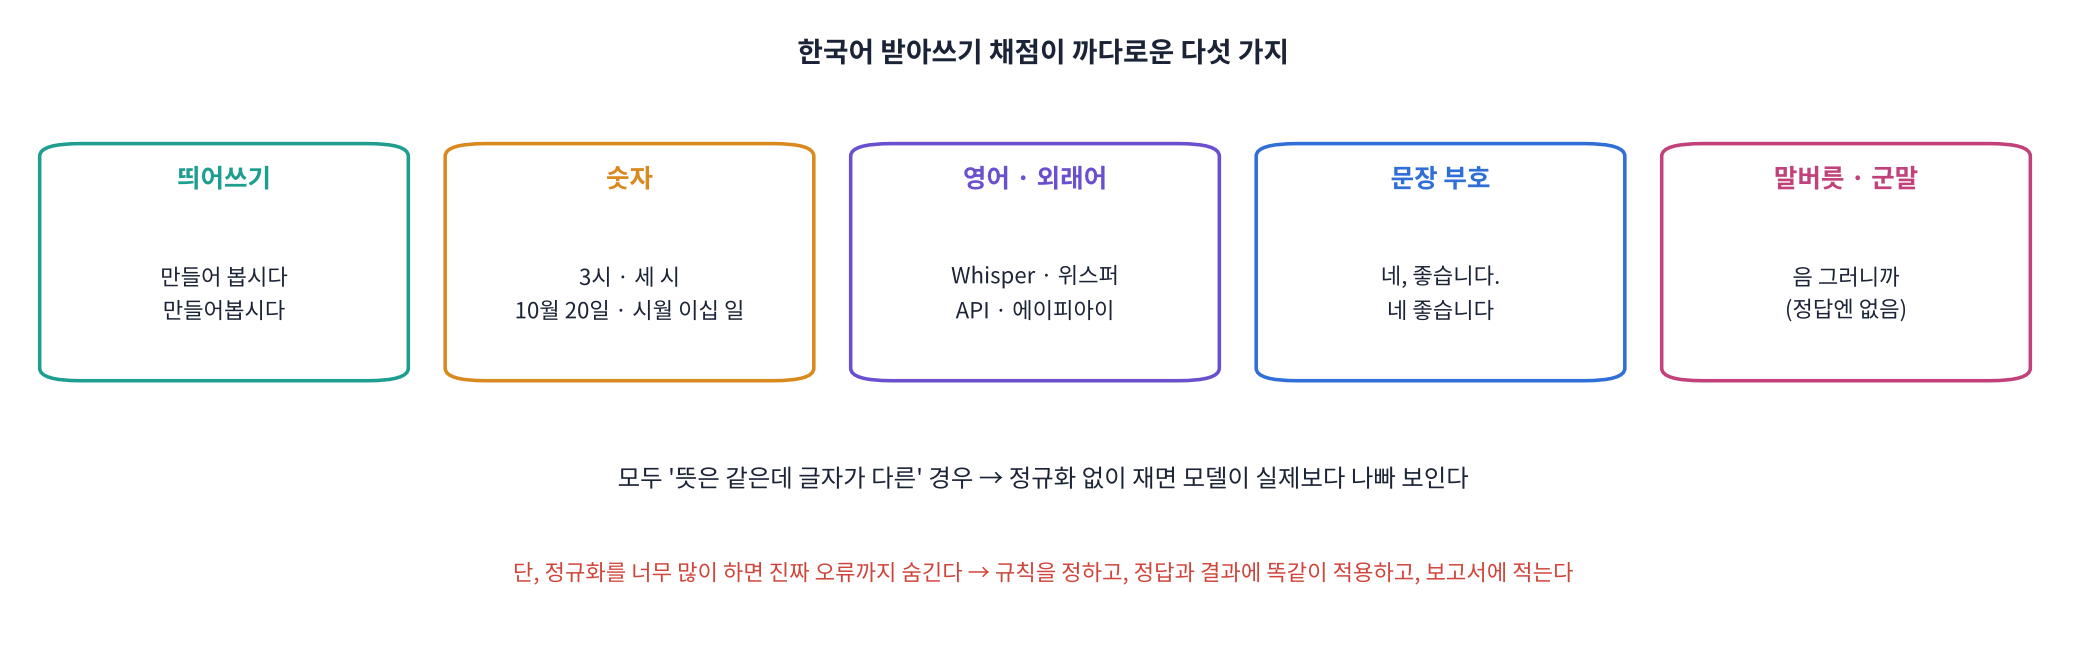

### 2-1. Whisper로 받아 적고 그대로 채점하기

In [ ]:
from faster_whisper import WhisperModel

fw = WhisperModel("small", device=DEVICE, compute_type=CT)
HYPS = [" ".join(s.text.strip() for s in fw.transcribe(c, language="ko", beam_size=5)[0]) for c in eval_clips]
for r, h in zip(REFS, HYPS):
    print(f"정답: {r}\n결과: {h}\n")

### 🧩 빈칸 실습 3: jiwer로 한꺼번에 채점하기
jiwer는 문장 목록을 통째로 받아 **전체** 오류율을 냅니다(문장마다 평균이 아니라, 전체 고침 횟수 ÷ 전체 정답 길이). 글자 오류율을 내는 함수 이름을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 3
raw_wer = jiwer.wer(REFS, HYPS)
raw_cer = jiwer.____(REFS, HYPS)
print(f"정규화 전: WER {raw_wer:.1%} · CER {raw_cer:.1%}\n")

out = jiwer.process_words(REFS, HYPS)
print(f"S {out.substitutions} · D {out.deletions} · I {out.insertions} · 맞음 {out.hits}")
print(jiwer.visualize_alignment(out, show_measures=False)[:900])
check(abs(raw_cer - jiwer.process_characters(REFS, HYPS).cer) < 1e-9, hint="글자 오류율 = Character Error Rate → jiwer.cer")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
raw_cer = jiwer.cer(REFS, HYPS)
```

**해설**: `visualize_alignment`는 문장마다 정답(REF)과 결과(HYP)를 줄 맞춰 보여 주고 S · D · I 위치를 표시합니다. 어떤 오류가 **진짜 잘못 들은 것**이고 어떤 오류가 **표기만 다른 것**(숫자 · 영어 · 문장 부호 · 띄어쓰기)인지 직접 구분해 보세요. 표기만 다른 오류가 많다면 정규화가 필요합니다.

</details>

### 2-2. 정규화 함수 만들기

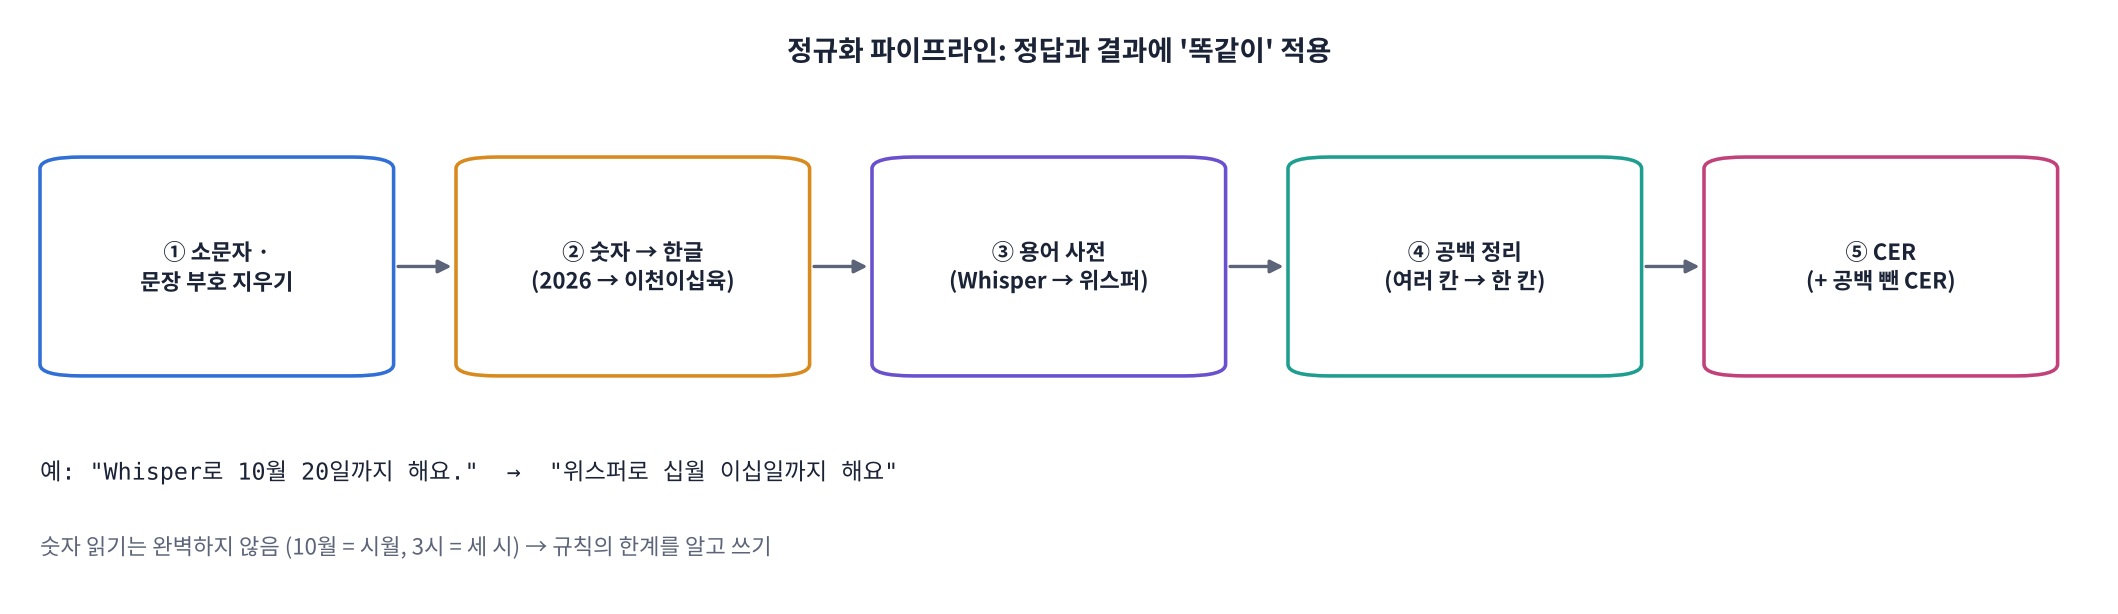

**👣 한 단계씩**
1. **소문자 · 문장 부호 지우기**: `Whisper` → `whisper`, `네, 좋습니다.` → `네 좋습니다`
2. **숫자 → 한글 읽기**: `2500` → `이천오백`, `3` → `삼` (한자어 읽기)
3. **용어 사전**: 영어 · 외래어를 한 가지 표기로 (`whisper` → `위스퍼`)
4. **공백 정리**: 여러 칸 공백을 한 칸으로, 앞뒤 공백 지우기

> 🍎 **비유: 맞춤법 채점 기준표.** 시험 전에 "숫자는 한글로 써도 정답, 쉼표는 안 봄"처럼 **기준표**를 정해 두고 모든 답안에 똑같이 적용합니다. 학생마다 기준을 바꾸면 공정하지 않습니다.

> 🎬 **애니메이션 D10-4:** [정규화 단계 켜고 끄기](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#norm) — 단계를 하나씩 켜며 CER이 어떻게 줄어드는지

### 🧩 빈칸 실습 4: 숫자를 한글로 읽기
`2026` → `이천이십육`처럼 **한자어 수사**로 읽는 함수입니다(9999까지). 오른쪽 자리부터 하나씩 보며 `숫자 + 자리 이름(십 · 백 · 천)`을 붙입니다. 자리 이름 목록 `UNITS`에서 **몇 번째 자리인지**를 나타내는 변수를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 4
DIG = "영일이삼사오육칠팔구"
UNITS = ["", "십", "백", "천"]

def num2kor(n):
    if n == 0:
        return "영"
    if n >= 10000:                                   # 만 이상은 오늘 다루지 않음 (그대로 둠)
        return str(n)
    s = ""
    for i, ch in enumerate(reversed(str(n))):        # i = 0(일의 자리), 1(십), 2(백), 3(천)
        d = int(ch)
        if d == 0:
            continue
        s = ("" if (d == 1 and i > 0) else DIG[d]) + UNITS[____] + s    # '일십' 대신 '십'
    return s

for n in [3, 10, 20, 2500, 2026, 1001]:
    print(n, "→", num2kor(n))
check(num2kor(2026) == "이천이십육" and num2kor(10) == "십" and num2kor(1001) == "천일", hint="자리 번호 i 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
s = ("" if (d == 1 and i > 0) else DIG[d]) + UNITS[i] + s
```

**해설**: `reversed(str(n))`로 일의 자리부터 보므로 `i`가 곧 자리 번호입니다. 십 · 백 · 천 자리의 1은 '일십'이 아니라 '십'으로 읽습니다. **한계**: '3시'는 실제로 '세 시'(고유어 수사)로 읽고, '10월'은 '시월'로 읽습니다. 이 함수는 둘 다 '삼시' · '십월'로 바꾸므로, Whisper가 '세 시'라고 적으면 여전히 다르게 셉니다. **완벽한 규칙은 없으니 한계를 알고 쓰고, 보고서에 규칙을 적는 것**이 중요합니다.

</details>

### 🧩 빈칸 실습 5 · 6: 용어 사전과 공백 정리
이제 네 단계를 하나로 묶습니다. 용어 사전은 **바꿀 말(k) → 바꿀 표기(v)** 입니다. 빈칸 5에는 바꿀 표기를, 빈칸 6에는 여러 칸 공백을 **한 칸**으로 바꿀 문자열을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 5 · 6
TERMS = {"whisper": "위스퍼", "api": "에이피아이", "cer": "씨이알", "pyannote": "파이아노트"}   # ✏️ 바꿔 보기: 우리 회사 용어

def normalize(s):
    s = s.lower()                                              # ① 소문자
    s = re.sub(r"(?<=\d),(?=\d)", "", s)                       #    2,500 → 2500 (숫자 속 쉼표)
    s = re.sub(r"[^\w\s]", " ", s)                             # ① 문장 부호 → 공백
    s = re.sub(r"\d+", lambda m: num2kor(int(m.group())), s)  # ② 숫자 → 한글
    for k, v in TERMS.items():
        s = s.replace(k, ____)                                 # ③ 용어 사전 (빈칸 5)
    s = re.sub(r"\s+", ____, s).strip()                        # ④ 공백 정리 (빈칸 6)
    return s

for r in REFS[:4]:
    print(f"{r}  →  {normalize(r)}")
check(normalize("Whisper로  10월 20일, API!") == "위스퍼로 십월 이십일 에이피아이", hint="빈칸 5는 v, 빈칸 6은 공백 한 칸 \" \" 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
s = s.replace(k, v)
s = re.sub(r"\s+", " ", s).strip()
```

**해설**: 순서가 중요합니다. 문장 부호를 공백으로 바꾸면 공백이 여러 칸 생기므로 **공백 정리는 맨 마지막**에 합니다. 용어 사전은 소문자로 바꾼 뒤에 적용하므로 키도 소문자로 씁니다. `20일`은 숫자만 바뀌어 `이십일`이 됩니다(띄어쓰기는 그대로).

</details>

### 2-3. 정규화 전후 비교

In [ ]:
rows = []
for r, h in zip(REFS, HYPS):
    nr, nh = normalize(r), normalize(h)
    rows.append(dict(정답=r, 결과=h, CER_전=jiwer.cer(r, h), CER_후=jiwer.cer(nr, nh),
                     CER_공백무시=jiwer.cer(nr.replace(" ", ""), nh.replace(" ", ""))))
df_cmp = pd.DataFrame(rows)
print(df_cmp.round(3).to_string())

NR, NH = [normalize(r) for r in REFS], [normalize(h) for h in HYPS]
tot = {"raw": jiwer.cer(REFS, HYPS), "normalized": jiwer.cer(NR, NH),
       "normalized, no space": jiwer.cer([x.replace(" ", "") for x in NR], [x.replace(" ", "") for x in NH])}
print("\n전체 CER:", {k: f"{v:.1%}" for k, v in tot.items()}, "| WER 정규화 후:", f"{jiwer.wer(NR, NH):.1%}")
plt.figure(figsize=(7, 2.4)); plt.barh(list(tot), [v * 100 for v in tot.values()], color=["gray", "tab:purple", "tab:pink"])
plt.xlabel("CER (%)"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

**결과 읽기**: 정규화 후 CER이 내려간 만큼이 **"표기만 다른" 오류**였습니다. 남은 오류가 모델이 **실제로 잘못 들은** 부분입니다. 보고서에는 **규칙과 함께** 두 숫자를 모두 적습니다: "CER 9.8% (정규화 전) / 4.1% (정규화 후: 소문자 · 문장 부호 제거 · 숫자 한글화 · 용어 사전 · 공백 정리)".

> 🎬 **애니메이션 D10-5:** [숫자 읽기 실험실](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#numbers) — 숫자를 넣어 한자어 읽기와 실제 읽기(세 시, 시월)를 비교

**❓ 생각해 보기**: 정규화를 아주 많이 하면(예: 조사 '은 · 는 · 이 · 가'를 모두 지우기) CER은 더 낮아집니다. 좋은 일일까요?

<details>
<summary>답 보기</summary>

아닙니다. **진짜 오류까지 숨깁니다.** '김팀장이 했다'와 '김팀장은 했다'는 뜻이 조금 다를 수 있고, 조사를 잘못 받아 적는 것도 모델의 실수입니다. 정규화는 **'뜻은 같고 표기만 다른 것'만** 맞추는 데 써야 합니다. 그리고 비교하는 모든 모델에 **똑같은 규칙**을 적용해야 공정합니다. 3주차(D14)에서 Fine-tuning 전후, 상용 API를 비교할 때 이 함수를 그대로 다시 씁니다.

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day10/worksheet.html)** — jiwer 함수들, 전체 CER의 계산 방식, 한국어 채점의 함정 다섯 가지, 정규화 단계와 순서, 숫자 읽기의 한계, 과한 정규화, 보고서에 규칙 적기
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 3. 🛠️ 미니 프로젝트 ①: 회의록 파이프라인 조립

> 💬 **쉽게 말하면**: D8 · D9에서 만든 부품을 **함수 하나** `make_minutes(audio)`로 묶습니다. 녹음을 넣으면 '누가 · 언제 · 무엇을' 말했는지 적힌 녹취와, Part 4의 요약까지 한 번에 나오게 합니다.

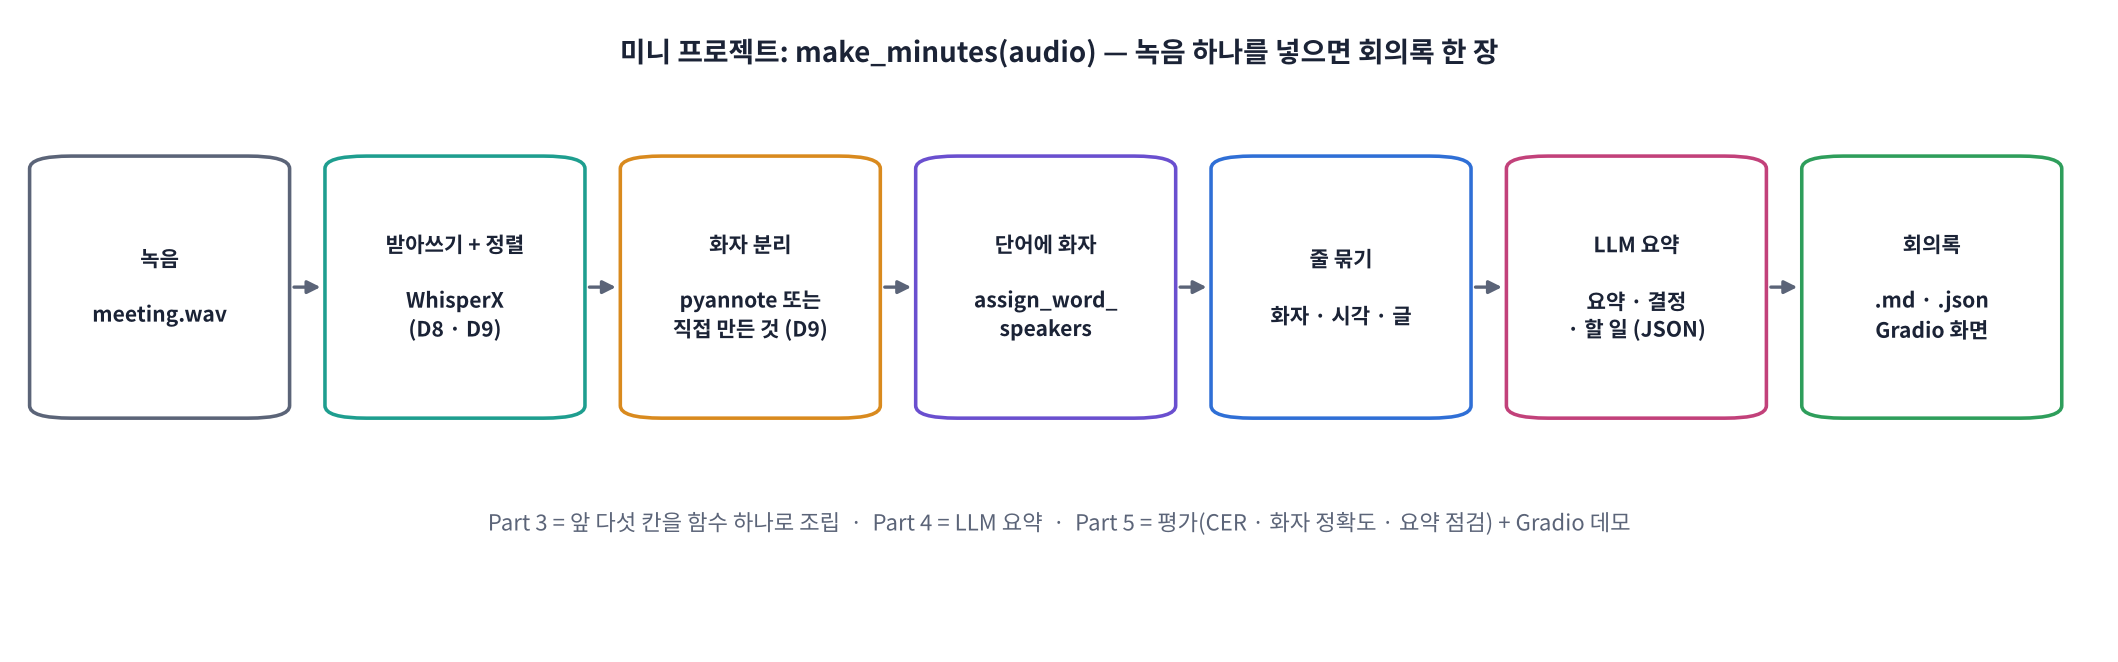

#### 프로젝트 요구사항
| 번호 | 요구사항 | 어디서 |
|---|---|---|
| R1 | 녹음 → 단어 시각이 있는 받아쓰기 | WhisperX (D9 Part 3) |
| R2 | 화자 구분 (토큰 있으면 pyannote, 없으면 직접 만든 것) | D9 Part 4 · 5 |
| R3 | `[분:초] 화자: 발언` 형식의 녹취 | D9 Part 6 |
| R4 | 요약 · 결정 사항 · 할 일(담당 · 기한) | Part 4 (LLM) |
| R5 | 평가표: CER(정규화 후) · 화자 정확도 · 요약 점검 | Part 5 |
| R6 | 데모 화면 (녹음 올리기 → 회의록) | Part 5 Gradio |

> 🎬 **애니메이션 D10-6:** [회의록 파이프라인](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#pipeline) — 단계마다 들어가고 나오는 것 확인

### 3-1. 부품 불러오기 (모델은 한 번만)

In [ ]:
import whisperx
from whisperx.diarize import DiarizationPipeline
from speechbrain.inference.speaker import EncoderClassifier
from sklearn.cluster import AgglomerativeClustering

wx = whisperx.load_model("small", DEVICE, compute_type=CT, language="ko")                 # R1 받아쓰기
align_model, meta = whisperx.load_align_model(language_code="ko", device=DEVICE)          # R1 정렬
spk_enc = EncoderClassifier.from_hparams(source="speechbrain/spkrec-ecapa-voxceleb", savedir="ecapa", run_opts={"device": DEVICE})
pya = DiarizationPipeline(token=HF_TOKEN, device=DEVICE) if HF_TOKEN else None            # R2 (토큰 있을 때)
print("부품 준비 완료 | 화자 분리:", "pyannote" if pya else "직접 만든 것")

In [ ]:
# R1 · R2 · R3: 함수 세 개 (D9 코드를 함수로 정리)
def embed(y):
    with torch.no_grad():
        e = spk_enc.encode_batch(torch.from_numpy(np.ascontiguousarray(y)).float()[None].to(DEVICE))
    return e.squeeze().cpu().numpy()

def transcribe_align(y):
    result = wx.transcribe(y, batch_size=8, language="ko")
    return whisperx.align(result["segments"], align_model, meta, y, DEVICE, return_char_alignments=False)

def diarize(y, num_speakers=None):
    if pya is not None:
        return pya(y, num_speakers=num_speakers)[["start", "end", "speaker"]]
    iv = librosa.effects.split(y, top_db=30, frame_length=1024, hop_length=256) / SR      # D9 Part 4
    segs = []
    for a, b in iv:
        if segs and a - segs[-1][1] < 0.3: segs[-1][1] = b
        else: segs.append([a, b])
    segs = [(a, b) for a, b in segs if b - a > 0.3]
    E = np.stack([embed(y[int(a * SR):int(b * SR)]) for a, b in segs])
    cl = (AgglomerativeClustering(n_clusters=num_speakers, metric="cosine", linkage="average") if num_speakers
          else AgglomerativeClustering(n_clusters=None, distance_threshold=0.6, metric="cosine", linkage="average"))   # ✏️ 바꿔 보기
    labels = cl.fit_predict(E) if len(segs) > 1 else [0]
    return pd.DataFrame([dict(start=a, end=b, speaker=f"SPEAKER_{k:02d}") for (a, b), k in zip(segs, labels)])

def to_lines(aligned, diar):
    res = whisperx.assign_word_speakers(diar, aligned, fill_nearest=True)
    words = [w for s in res["segments"] for w in s.get("words", []) if w.get("start") is not None]
    lines = []
    for w in words:                                                   # D9 빈칸 9: 같은 화자면 이어 붙이기
        spk = w.get("speaker", "?")
        if lines and lines[-1]["speaker"] == spk:
            lines[-1]["text"] += " " + w["word"]; lines[-1]["end"] = w["end"]
        else:
            lines.append(dict(speaker=spk, start=w["start"], end=w["end"], text=w["word"]))
    return lines, words

### 🧩 빈칸 실습 7: 시각을 `분:초`로 쓰기
회의록에는 `[03:25]`처럼 **분:초**로 적습니다. 205초 → 3분 25초. 초 자리는 **60으로 나눈 나머지**입니다.

In [ ]:
# 🧩 빈칸 실습 7
def fmt_time(t):
    return f"{int(t // 60):02d}:{int(t % ____):02d}"

t0 = time.time()
aligned = transcribe_align(meeting)
diar = diarize(meeting, num_speakers=3)                               # 화자 수를 알면 알려 주기 (모르면 None)
lines, words = to_lines(aligned, diar)
print(f"처리 {time.time() - t0:.1f}초 (녹음 {len(meeting) / SR:.1f}초) | 화자 분리 구간 {len(diar)}개 | 줄 {len(lines)}개\n")
for ln in lines:
    print(f"[{fmt_time(ln['start'])}] {ln['speaker']}: {ln['text']}")
check(fmt_time(205) == "03:25" and fmt_time(59.9) == "00:59", hint="1분 = 60초. 초 자리는 t % 60 입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return f"{int(t // 60):02d}:{int(t % 60):02d}"
```

**해설**: `//`는 몫(분), `%`는 나머지(초)입니다. `:02d`는 두 자리로 맞추고 빈자리를 0으로 채웁니다(3 → 03). 한 시간이 넘는 회의라면 `시:분:초`로 늘리면 됩니다(D9의 SRT 시각 함수처럼).

</details>

### 3-2. 번호에 이름 붙이기 (D9 6-2)
등록 음성이 있으면 `SPEAKER_00` 대신 이름을 씁니다. 없으면 번호 그대로 둡니다.

In [ ]:
from scipy.optimize import linear_sum_assignment

def cosine(a, b):
    return float(a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

def name_speakers(y, diar, enroll=None):
    labs = sorted(set(diar["speaker"]))
    if not enroll:
        return {l: l for l in labs}
    names = list(enroll)
    E_en = [embed(enroll[n]) for n in names]
    E_lab = []
    for l in labs:
        s = diar[diar["speaker"] == l]
        E_lab.append(embed(np.concatenate([y[int(a * SR):int(b * SR)] for a, b in zip(s["start"], s["end"])])[:SR * 20]))
    sim = np.array([[cosine(a, b) for b in E_en] for a in E_lab])
    r, c = linear_sum_assignment(-sim)
    m = {labs[i]: names[j] for i, j in zip(r, c)}
    return {l: m.get(l, l) for l in labs}

NAME = name_speakers(meeting, diar, ENROLL)
print("이름 붙이기:", NAME)
for ln in lines:
    ln["name"] = NAME.get(ln["speaker"], ln["speaker"])
transcript = "\n".join(f"[{fmt_time(ln['start'])}] {ln['name']}: {ln['text']}" for ln in lines)
print("\n" + transcript)

**❓ 생각해 보기**: 화자 수를 모를 때 `diarize(meeting)`처럼 `num_speakers=None`으로 부르면 어떻게 될까요?

<details>
<summary>답 보기</summary>

pyannote면 모델이 화자 수를 스스로 정하고, 직접 만든 것이면 `distance_threshold=0.6` 기준으로 멈춥니다(D9 D9-6 애니메이션). 기준이 맞지 않으면 화자가 둘로 합쳐지거나 넷으로 쪼개집니다. 시간이 남으면 직접 불러 보고 결과를 비교해 보세요. 실제 서비스에서는 '회의 참석자 수'를 입력받는 칸을 두는 경우가 많습니다(Part 5 Gradio 화면의 '화자 수').

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day10/worksheet.html)** — 파이프라인 단계 순서, 각 단계의 입력 · 출력, 모델을 한 번만 불러 두는 이유, 화자 수를 알 때와 모를 때, 이름 붙이기, `분:초` 계산
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 4. 🛠️ 미니 프로젝트 ②: LLM으로 요약 · 결정 사항 · 할 일

> 💬 **쉽게 말하면**: 녹취 전체를 읽는 사람은 없습니다. **LLM(Claude)** 에게 녹취를 주고 '요약 3줄, 결정 사항, 할 일(담당 · 기한)'을 **정해진 JSON 모양**으로 달라고 합니다. 모양이 정해져 있어야 코드가 받아서 표로 만들 수 있습니다.

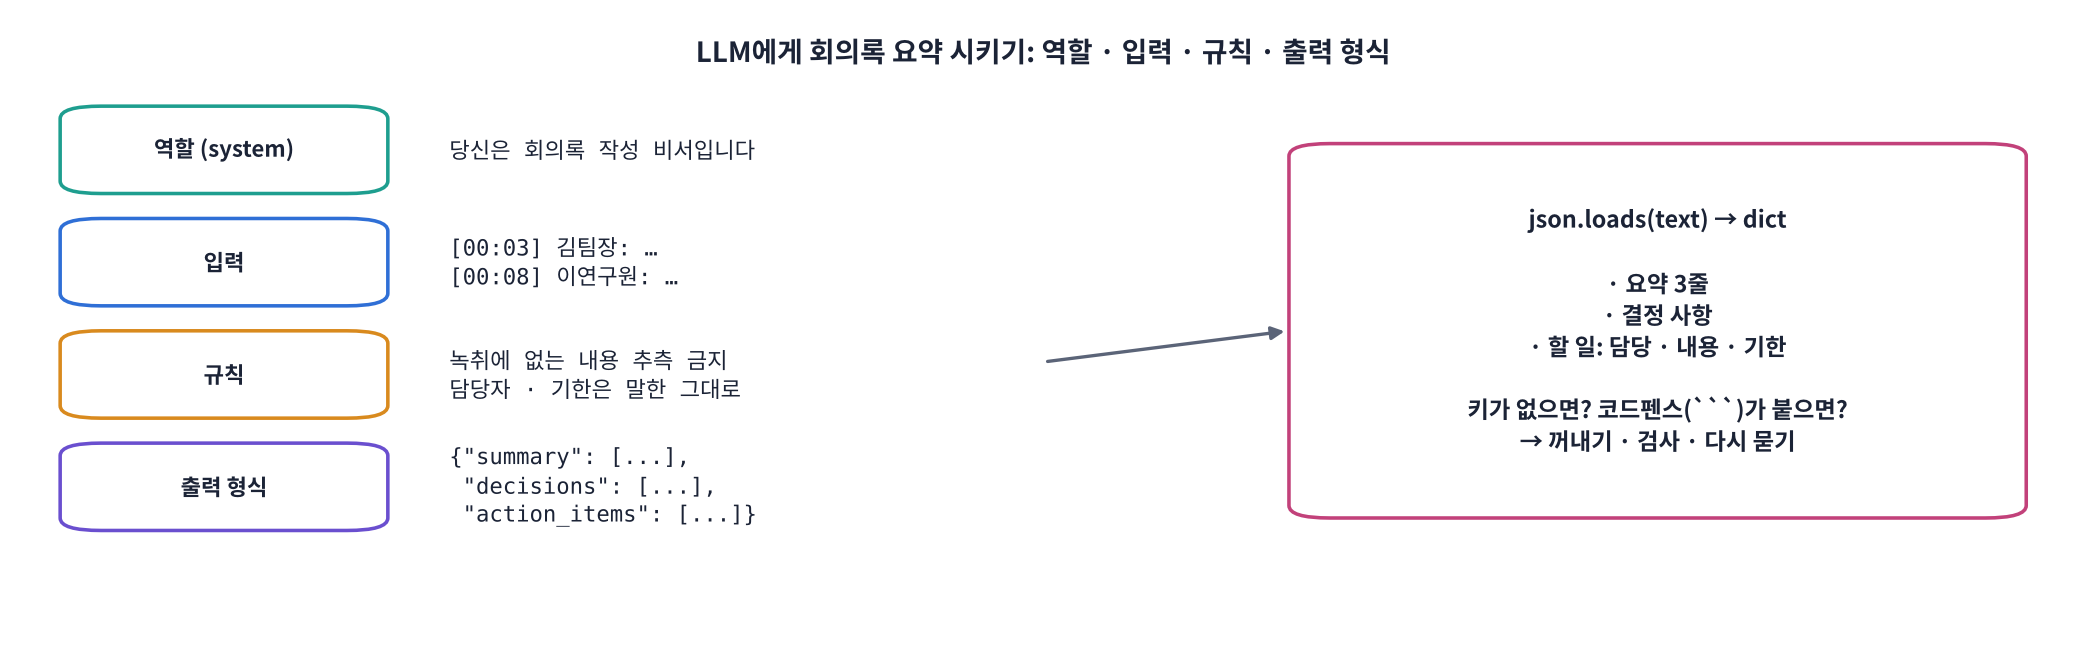

> 🍎 **비유: 비서에게 회의록 정리 부탁하기.** "요약 좀 해 줘"보다 "**이 양식**에 맞춰, **녹음에 없는 말은 지어내지 말고**, 할 일은 **누가 · 언제까지**를 꼭 적어 줘"라고 부탁해야 원하는 결과가 나옵니다. 양식이 정해져 있으면 받은 뒤 정리도 쉽습니다.

| 프롬프트 부분 | 오늘의 내용 | 왜 |
|---|---|---|
| 역할 (system) | 회의록 작성 비서 | 말투 · 관점 고정 |
| 입력 | `[분:초] 이름: 발언` 녹취 | 시각 · 화자를 함께 줘야 '누가 맡았나'를 알 수 있음 |
| 규칙 | 녹취에 없는 내용 추측 금지, 담당 · 기한은 말한 그대로, 받아쓰기 오류는 문맥으로 보정 | 환각(D7) 막기 |
| 출력 형식 | JSON 키 `summary` · `decisions` · `action_items` | 코드가 `json.loads`로 받기 |

> 🎬 **애니메이션 D10-7:** [프롬프트 만들기](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#prompt) — 규칙을 하나씩 켜며 결과가 어떻게 달라지는지

### 4-1. 프롬프트와 Claude 부르기

In [ ]:
SYSTEM = "당신은 한국어 회의록을 정리하는 비서입니다. 녹취에 없는 내용은 절대 지어내지 않습니다."
MODEL = "claude-haiku-5-5"            # ✏️ 바꿔 보기: 더 꼼꼼한 요약은 "claude-sonnet-5-5"

def build_prompt(transcript):
    return f"""아래는 음성 인식으로 만든 회의 녹취입니다. 받아쓰기 오류가 있을 수 있으니 문맥으로 이해하세요.

<녹취>
{transcript}
</녹취>

다음 JSON 형식으로만 답하세요. 다른 말은 쓰지 마세요.
{{"summary": ["요약 문장 (3개 이내)"],
 "decisions": ["결정된 사항"],
 "action_items": [{{"owner": "담당자 이름", "task": "할 일", "due": "기한 (말하지 않았으면 빈 문자열)"}}]}}

규칙: 녹취에 없는 내용은 쓰지 않습니다. 담당자와 기한은 녹취에서 말한 그대로 씁니다."""

def call_claude(prompt):
    import anthropic
    client = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)
    msg = client.messages.create(model=MODEL, max_tokens=1500, system=SYSTEM,
                                 messages=[{"role": "user", "content": prompt}])
    return next(b.text for b in msg.content if b.type == "text")

prompt = build_prompt(transcript)
print(prompt[:600], "…")

### 4-2. 규칙 기반 요약 (API 키가 없을 때의 대안)
키워드로 결정 사항과 할 일을 골라내는 간단한 방법입니다. LLM과 결과를 비교하면 **LLM이 무엇을 더 잘하는지** 보입니다.

In [ ]:
DAYS = ["월요일", "화요일", "수요일", "목요일", "금요일", "다음 주", "오늘", "내일"]

def rule_based_summary(lines):
    decisions, actions = [], []
    for ln in lines:
        for t in re.split(r"(?<=[.?!])\s+", ln["text"]):            # 한 줄을 문장으로 나눠서 봄
            if any(k in t for k in ["결정", "정했", "쓰기로", "하기로"]):
                decisions.append(t)
            due = next((d for d in DAYS if d in t), "")
            if due and any(k in t for k in ["겠습니다", "합시다", "까지"]):
                actions.append(dict(owner=ln.get("name", ln["speaker"]), task=t, due=due))
    summary = [f"발언 {len(lines)}건, 참석자 {len(set(l.get('name', l['speaker']) for l in lines))}명",
               f"결정 사항 {len(decisions)}건, 할 일 {len(actions)}건"]
    return dict(summary=summary, decisions=decisions, action_items=actions)

print(json.dumps(rule_based_summary(lines), ensure_ascii=False, indent=1)[:700])

### 🧩 빈칸 실습 8: LLM 답에서 JSON 꺼내기
LLM은 가끔 JSON 앞뒤에 ```` ```json ```` 같은 **코드펜스**를 붙입니다. 펜스를 떼어 낸 뒤, **JSON 문자열 → 파이썬 dict**로 바꾸는 `json` 모듈의 함수를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 8
def parse_json(text):
    text = text.strip()
    if text.startswith("```"):                                   # ```json ... ``` 떼어 내기
        text = text.split("\n", 1)[1].rsplit("```", 1)[0]
    data = json.____(text)
    for k in ["summary", "decisions", "action_items"]:          # 키 검사: 없으면 빈 목록
        data.setdefault(k, [])
    return data

def summarize(lines, transcript):
    if ANTHROPIC_API_KEY:
        try:
            return parse_json(call_claude(build_prompt(transcript))), "Claude"
        except Exception as e:
            print("⚠️ LLM 요약 실패 → 규칙 기반으로 대신:", str(e)[:120])
    return rule_based_summary(lines), "규칙 기반"

SUMMARY, how = summarize(lines, transcript)
print("요약 방법:", how)
print(json.dumps(SUMMARY, ensure_ascii=False, indent=1))
check(parse_json('```json\n{"summary": ["a"]}\n```') == {"summary": ["a"], "decisions": [], "action_items": []},
      hint="JSON 문자열을 읽는 함수: json.loads (load + s = string)")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
data = json.loads(text)
```

**해설**: `json.loads`는 **문자열**을, `json.load`는 **파일**을 읽습니다(s = string). LLM 답은 늘 완벽한 JSON이라는 보장이 없으므로 ① 펜스 떼기 ② 읽기 ③ 키 검사 ④ 실패하면 대안(규칙 기반)으로 넘어가기를 꼭 둡니다. 더 확실하게 하려면 Claude API의 **도구 사용(tool use) + JSON 스키마(strict)** 로 형식을 강제할 수 있습니다. 이 방법은 D23 Tool Calling에서 배웁니다.

</details>

### 4-3. 회의록 문서 만들기

In [ ]:
def render_minutes(summary, lines, title="회의록 (자동 생성)"):
    md = [f"# {title}", "", "## 요약"] + [f"- {s}" for s in summary["summary"]]
    md += ["", "## 결정 사항"] + ([f"- {d}" for d in summary["decisions"]] or ["- (없음)"])
    md += ["", "## 할 일", "| 담당 | 할 일 | 기한 |", "|---|---|---|"]
    md += [f"| {a.get('owner', '')} | {a.get('task', '')} | {a.get('due', '')} |" for a in summary["action_items"]] or ["| - | - | - |"]
    md += ["", "## 녹취"] + [f"- **[{fmt_time(l['start'])}] {l.get('name', l['speaker'])}**: {l['text']}" for l in lines]
    return "\n".join(md)

MINUTES_MD = render_minutes(SUMMARY, lines)
open("meeting_minutes.md", "w", encoding="utf-8").write(MINUTES_MD)
json.dump(dict(summary=SUMMARY, lines=lines), open("meeting_minutes.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
display(Markdown(MINUTES_MD))

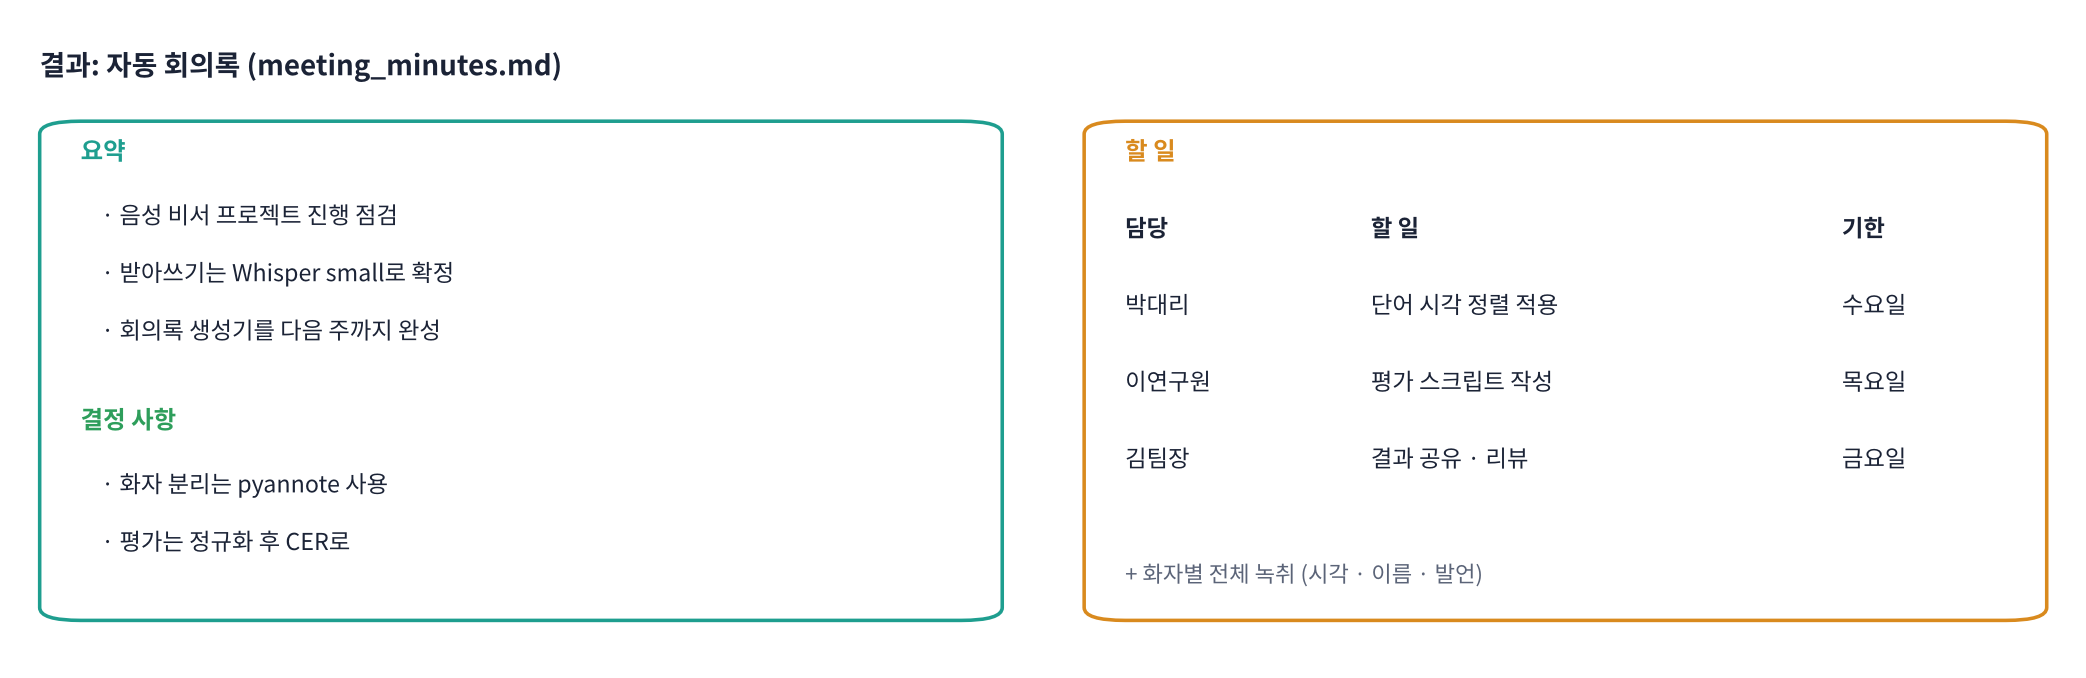

**❓ 생각해 보기**: LLM 요약에서 '담당자: 박대리, 기한: 수요일'이 나왔는데 실제로는 이연구원이 맡은 일이었다면, 어디서 잘못됐을 가능성이 클까요?

<details>
<summary>답 보기</summary>

세 군데를 의심합니다. ① **화자 분리 · 이름 붙이기**가 틀려 녹취의 이름이 바뀐 경우(가장 흔함), ② **받아쓰기**가 '목요일'을 '수요일'로 잘못 들은 경우, ③ **LLM**이 문맥을 잘못 읽은 경우. 그래서 Part 5에서 **단계마다 따로** 평가합니다. 최종 결과만 보고는 어느 단계를 고쳐야 할지 모릅니다.

</details>

## Part 5. 🛠️ 미니 프로젝트 ③: 평가 · 데모 · 발표

> 💬 **쉽게 말하면**: 회의록 생성기의 품질은 **세 단계로 나눠** 잽니다. 받아쓰기(CER, 정규화 후), 화자(단어별 화자 정확도), 요약(핵심 사항을 몇 개나 담았나). 오늘은 정답(`SCRIPT`, `TURNS`)을 알고 있으니 셋 다 잴 수 있습니다.

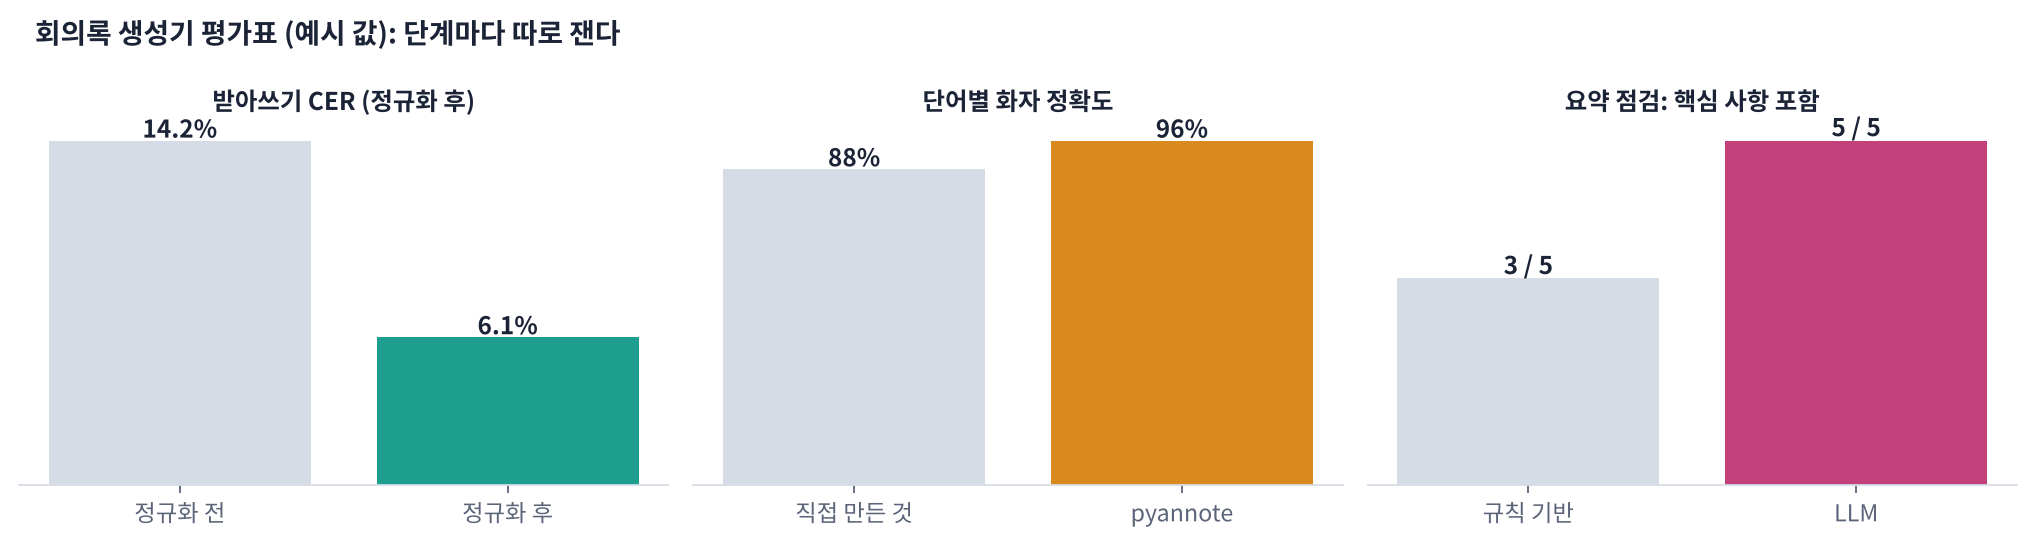

> 🎬 **애니메이션 D10-8:** [평가표](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#eval) — 단계별 점수를 바꿔 보며 최종 회의록 품질이 어떻게 달라지는지

### 🧩 빈칸 실습 9: 요약 점검 점수
회의의 **핵심 사항 다섯 개**(`KEY_POINTS`)가 요약 JSON에 들어 있는지 키워드로 확인합니다. 찾은 개수를 **핵심 사항 전체 개수**로 나눕니다.

In [ ]:
# 🧩 빈칸 실습 9
KEY_POINTS = {                                         # 핵심 사항: 이 중 하나라도 나오면 '담음'
    "받아쓰기 모델 = 위스퍼 스몰": ["위스퍼", "whisper"],
    "화자 분리 = 파이아노트": ["파이아노트", "pyannote"],
    "평가 = 정규화 후 글자 오류율": ["오류율", "cer"],
    "박대리 · 수요일 · 단어 시각 정렬": ["수요일"],
    "이연구원 · 목요일 · 평가 스크립트": ["목요일"],
}
summary_text = normalize(json.dumps(SUMMARY, ensure_ascii=False))
found = {k: any(normalize(w) in summary_text for w in kws) for k, kws in KEY_POINTS.items()}
score = sum(found.values()) / len(____)

# 받아쓰기 · 화자 평가
hyp_text = " ".join(w["word"] for w in words)
cer_raw, cer_norm = jiwer.cer(REF_MEETING, hyp_text), jiwer.cer(normalize(REF_MEETING), normalize(hyp_text))
def turn_of(t):
    d = [0 if x["start"] <= t <= x["end"] else min(abs(t - x["start"]), abs(t - x["end"])) for x in TURNS]
    return int(np.argmin(d))
spk_acc = np.mean([NAME.get(w.get("speaker"), "?") == TURNS[turn_of((w["start"] + w["end"]) / 2)]["speaker"] for w in words])

print("📋 평가표")
print(f"  받아쓰기 CER   정규화 전 {cer_raw:.1%} → 정규화 후 {cer_norm:.1%}")
print(f"  단어별 화자 정확도 {spk_acc:.1%}")
print(f"  요약 점검 {sum(found.values())}/{len(found)} ({how})")
for k, v in found.items():
    print(f"    {'✅' if v else '⬜'} {k}")
check(abs(score - sum(found.values()) / 5) < 1e-9, hint="핵심 사항 전체 = KEY_POINTS 의 개수")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
score = sum(found.values()) / len(KEY_POINTS)
```

**해설**: `found.values()`는 True/False 목록이라 `sum`하면 찾은 개수가 됩니다. 규칙 기반 요약은 '위스퍼'처럼 발언에 그대로 있는 단어만 옮겨 담아 점수가 낮게 나오기 쉽고, LLM 요약은 문장을 다듬으면서 핵심을 모아 담습니다. 단, 키워드 검사는 **거친 점검**일 뿐이라 '수요일'이 엉뚱한 사람의 할 일로 들어가도 점수를 줍니다. 최종 판단은 사람이 회의록을 읽고 합니다(발표 때 서로 확인).

</details>

### 5-1. 하나로 묶기: `make_minutes()`

In [ ]:
def make_minutes(y, num_speakers=None, enroll=None):
    aligned = transcribe_align(y)                                   # R1
    diar = diarize(y, num_speakers)                                 # R2
    lines, words = to_lines(aligned, diar)                          # R3
    name = name_speakers(y, diar, enroll)
    for ln in lines:
        ln["name"] = name.get(ln["speaker"], ln["speaker"])
    transcript = "\n".join(f"[{fmt_time(l['start'])}] {l['name']}: {l['text']}" for l in lines)
    summary, how = summarize(lines, transcript)                     # R4
    return render_minutes(summary, lines, title=f"회의록 (자동 생성 · 요약: {how})"), summary

t0 = time.time()
md_out, _ = make_minutes(meeting, num_speakers=3, enroll=ENROLL)
print(f"전체 {time.time() - t0:.1f}초")
display(Markdown(md_out[:1500]))

### 5-2. Gradio 데모 화면 (R6)
녹음 파일을 올리면 회의록이 나오는 웹 화면입니다. 실행하면 `https://….gradio.live` 공유 링크가 생깁니다(72시간 유지). 옆 사람에게 링크를 보내 **자기 목소리로** 시험해 보게 하세요. 셀을 멈추려면 ■(중지)를 누릅니다.

> 🎬 **애니메이션 D10-9:** [회의록 생성기 화면](https://imguru-mooc.github.io/AI_Voice/day10/animation.html#demo) — 완성된 화면이 어떻게 보이는지 미리 보기

In [ ]:
import gradio as gr

def run_demo(audio_path, n_spk):
    if not audio_path:
        return "녹음 파일을 올려 주세요."
    y, _ = librosa.load(audio_path, sr=SR, mono=True)
    md_out, _ = make_minutes(y.astype(np.float32), num_speakers=int(n_spk) if n_spk else None)
    return md_out

demo = gr.Interface(
    fn=run_demo,
    inputs=[gr.Audio(type="filepath", label="회의 녹음 (wav · mp3 · 마이크)"),
            gr.Number(value=0, precision=0, label="화자 수 (모르면 0)")],
    outputs=gr.Markdown(label="회의록"),
    title="🎙️ 자동 회의록 생성기 (D10 미니 프로젝트)",
    description="WhisperX 받아쓰기 → 화자 분리 → 요약 · 결정 사항 · 할 일",
)
demo.launch(share=True)

### 5-3. 🎤 발표 (팀당 3분)
1. **데모**: Gradio 화면에서 녹음 하나를 넣어 회의록이 나오는 모습 (오늘 녹음 또는 직접 녹음)
2. **평가표**: CER(정규화 전 · 후) · 화자 정확도 · 요약 점검 점수
3. **가장 많이 틀린 곳 하나**와 원인 (받아쓰기 / 화자 / 요약 중 어디?), 고친다면 어떻게?
4. ✏️ **내가 바꾼 것** (용어 사전, 거리 기준, 프롬프트 규칙, 모델 등)

> 📐 **채점 기준 (미니 프로젝트 30% 중 이번 회차)**: 동작하는 데모 40 · 평가표 30 · 오류 분석 20 · 개선 시도 10

---
### 📝 4교시 마무리: 개념 워크시트 · 제출

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day10/worksheet.html)** — 프롬프트의 네 부분, JSON 출력과 `json.loads`, 코드펜스 · 키 검사 · 대안, 환각 막는 규칙, 단계별 평가, 키워드 점검의 한계, Gradio 데모
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 6. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| WER · CER | (S + D + I) ÷ 정답 길이, 100%를 넘을 수 있음 | `jiwer.wer`, `jiwer.cer` |
| 편집 거리 | 표의 세 방향 중 최소 (빠짐 · 끼어듦 · 바꿈) | `d[i-1, j-1] + cost` |
| 한국어는 CER | 띄어쓰기가 WER을 크게 흔듦 | 공백 뺀 CER도 함께 |
| 정규화 | 소문자 · 문장 부호 · 숫자 · 용어 · 공백, 정답과 결과에 똑같이 | `normalize(s)` |
| 숫자 읽기 | 한자어 읽기 함수, '세 시' · '시월'은 한계 | `num2kor(2026)` |
| 파이프라인 | 받아쓰기 · 정렬 → 화자 분리 → 단어에 화자 → 줄 묶기 | `make_minutes(y)` |
| LLM 요약 | 역할 · 입력 · 규칙 · JSON 형식, 펜스 떼기 · 키 검사 · 대안 | `json.loads` |
| 단계별 평가 | CER · 화자 정확도 · 요약 점검 | `KEY_POINTS` |
| 데모 | 녹음 올리기 → 회의록 | `gr.Interface(...).launch(share=True)` |

### 📝 과제
1. **내 회의록 생성기 개선**: 다음 중 하나를 골라 고치고, 평가표가 어떻게 바뀌었는지 전후 비교하세요. ① 용어 사전에 우리 회사 · 수업 용어 10개 추가 ② `distance_threshold` 조정 ③ 프롬프트 규칙 추가(예: "할 일은 동사로 시작") ④ `MODEL`을 바꿔 요약 비교.
2. **진짜 회의로**: 동의를 받은 2~3명의 5분 회의 녹음으로 회의록을 만들고, 사람이 읽고 고친 '정답 회의록'과 비교해 틀린 곳 3개를 원인별(받아쓰기 · 화자 · 요약)로 분류하세요.
3. **정규화 보고서**: Part 2의 6문장에 내가 만든 문장 4개를 더해 정규화 전 · 후 CER을 표로 정리하고, 정규화 규칙을 한 줄씩 적으세요(3주차 D14에서 그대로 씁니다).

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D10 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day10/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. 미니 프로젝트 발표 자료(평가표 · 회의록 캡처)도 같은 페이지에 붙입니다.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day10/animation.html) — D10-1 ~ D10-9

### 다음 주 (3주차 · D11)
2주차에 Whisper를 **있는 그대로** 잘 쓰는 법을 배웠습니다. 3주차는 **우리 데이터로 Whisper를 고쳐 쓰기**(Fine-tuning)입니다. D11에서는 AIHub · KsponSpeech · Zeroth-Korean 같은 **한국어 음성 데이터셋**을 불러와 전처리합니다. 오늘 만든 `normalize()`가 데이터 정리와 평가에 다시 등장합니다.